# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Teninlanimi/flyrank-interenship-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*



### Research question

Can machine learning improve the prioritization of content refresh opportunities compared with a simple baseline scoring rule?

### Decision this supports

The goal is not to automatically decide which pages should be changed. The goal is to help a content team decide **which pages deserve human review first**.

The analysis compares several models against a simple baseline and evaluates them using ranking metrics, especially Precision@K. This reflects the practical question: *If a team can only review a small number of pages, how many of the highest-ranked pages are actually associated with observed declining performance?*

The primary evaluation focuses on client-grouped validation so that pages from the same client are not split across training and test folds. This provides a more realistic estimate of how the ranking approach may generalize to previously unseen clients.

### Research framing

This is an observational, decision-support study. The analysis measures associations in the available historical data; it does not establish that refreshing a page will cause traffic or search performance to improve.

In [80]:
# Section 1 — research question and study setup

RESEARCH_QUESTION = (
    "Can machine learning improve the prioritization of content refresh "
    "opportunities compared with a simple baseline scoring rule?"
)

PRIMARY_DECISION = (
    "Prioritize pages for human review when deciding which content "
    "refresh opportunities to investigate first."
)

PRIMARY_METRIC = "Precision@K"
PRIMARY_K_VALUES = [20, 50, 100]

print("Research question:")
print(RESEARCH_QUESTION)
print("\nDecision supported:")
print(PRIMARY_DECISION)
print("\nPrimary metric:", PRIMARY_METRIC)
print("K values:", PRIMARY_K_VALUES)

Research question:
Can machine learning improve the prioritization of content refresh opportunities compared with a simple baseline scoring rule?

Decision supported:
Prioritize pages for human review when deciding which content refresh opportunities to investigate first.

Primary metric: Precision@K
K values: [20, 50, 100]


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*



### Dataset and release

This study uses the public-safe, pseudonymized FlyRank ML Internship warehouse release:

`flyrank_pseudonymized_warehouse_release_v20260703`

The analysis uses two related tables:

- `dim_content` — content-level attributes and metadata.
- `fact_content_daily_performance` — daily search/performance observations.

The daily performance table contains approximately 79 million rows and covers historical observations from 2025 into June 2026. The warehouse export used in this analysis has a freshness cutoff at June 30, 2026.

### Analysis window

The modeling dataset is based on the prepared content-level analytical table used throughout the internship. The starter analysis month is March 2026, with historical performance features calculated from the available observation window.

### What was excluded

The analysis excludes information that would not be appropriate for a public research artifact, including:

- client-identifying information;
- private search queries;
- private URLs;
- credentials, tokens, or other secrets;
- raw content that could identify a client or page.

Only pseudonymized identifiers and aggregate/content-level features required for the modeling task are retained in the public-facing analysis.

### Why the two tables matter

The content table and daily performance table have different grains. Content-level information represents a page/content entity, while the performance table contains repeated daily observations for those entities.

The daily data therefore cannot be joined to the content table without controlling the grain. The modeling dataset uses aggregated performance features so that each modeling row represents a content-level observation rather than accidentally duplicating a page across daily records.

### Public-safety framing

The results describe patterns measured in the internship dataset. They should not be interpreted as claims about any individual client, website, query, or private production system.

In [81]:
# Section 2 — data audit
# Adjust DATA_PATH only if your prepared modeling dataset is stored elsewhere.

from pathlib import Path
import pandas as pd

DATA_PATH = Path("../../data/raw/content_refresh_anonymized.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Dataset loaded successfully.")
    print("Shape:", df.shape)
    print("\nFirst 10 columns:")
    print(df.columns.tolist()[:10])
else:
    print(f"Dataset not found at: {DATA_PATH}")
    print("If the notebook is being run in Colab, update DATA_PATH to the prepared dataset location.")

Dataset loaded successfully.
Shape: (30000, 44)

First 10 columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count']


In [82]:
# Basic data-quality checks

if "df" in globals():
    print("Rows:", len(df))
    print("Columns:", len(df.columns))

    if "client_id" in df.columns:
        print("Unique clients:", df["client_id"].nunique())

    if "content_id" in df.columns:
        print("Unique content IDs:", df["content_id"].nunique())

    print("\nMissing values:")
    missing = df.isna().sum()
    print(missing[missing > 0].sort_values(ascending=False).head(20))

Rows: 30000
Columns: 44
Unique clients: 32
Unique content IDs: 30000

Missing values:
provider_used        21438
word_count_tier       7699
char_count            7699
word_count            7699
char_count_tier       7699
model_used            5733
trend_pct             3388
competition_level     2610
search_volume         2468
competition           2468
cpc                   2468
main_intent           2374
scroll_rate            125
dtype: int64


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*


### Modeling assumptions

The analysis makes four main assumptions:

1. Historical content and performance features contain useful information for prioritizing pages associated with declining performance.
2. The target label is an observed historical outcome rather than a causal measure of future traffic.
3. A ranking metric is more useful for the operational decision than accuracy alone because the practical use case is to review a limited number of pages.
4. Client-level separation is necessary to reduce the risk that the model benefits from seeing related pages from the same client during training.

### Target definition

The target is:

`is_declining_label = 1` when `trend_direction == "down"`.

All other observed trend directions are treated as non-declining for this binary classification task.

The resulting label therefore represents whether the content record was associated with a measured downward trend in the prepared dataset.

### Features

The modeling pipeline uses numeric and categorical content/performance features available before the target outcome.

The feature set includes signals such as:

- content age;
- days since last update;
- impressions;
- average search position;
- click-through rate;
- word count;
- content type;
- search intent;
- provider/model metadata where retained in the prepared dataset.

Features that directly encode the target or would only be known after the prediction point are excluded.

### Baseline

The baseline represents a simple rule-based prioritization approach. It provides a reference point for determining whether machine learning adds value beyond an interpretable existing scoring rule.

The baseline is evaluated on the same test folds as the machine-learning models.

### Models

The evaluated approaches include:

- Baseline
- Decision Tree
- Logistic Regression
- Random Forest

The purpose is comparison rather than exhaustive hyperparameter optimization.

### Validation design

The primary validation design is **5-fold GroupKFold grouped by `client_id`**.

This means that a client appears in either the training or test portion of a fold, but not both. This is important because ordinary random splitting could allow the model to learn client-specific patterns and then encounter related records from the same client during evaluation.

The primary ranking metric is Precision@K for K = 20, 50, and 100.

### Leakage checks

Before evaluation, the feature set was audited for:

- target leakage;
- post-outcome variables;
- identifiers that could act as client memorization shortcuts;
- features derived from the target;
- train/test feature mismatches.

The final evaluation uses only features available to the modeling pipeline before the outcome being predicted.

### Evaluation principle

The model is selected according to the decision it is intended to support.

A model with strong general classification metrics is not automatically the best prioritization model. For this use case, the ability to place relevant pages near the top of the review queue is the primary consideration.

In [83]:
# Section 3 — target, feature groups, and validation setup

import numpy as np
import pandas as pd

TARGET = "is_declining_label"
GROUP_COLUMN = "client_id"

# Create the binary target if it has not already been created.
if TARGET not in df.columns:
    if "trend_direction" not in df.columns:
        raise KeyError(
            "Neither 'is_declining_label' nor 'trend_direction' is available."
        )

    df[TARGET] = (
        df["trend_direction"]
        .astype(str)
        .str.lower()
        .eq("down")
        .astype(int)
    )

print("Target distribution:")
print(df[TARGET].value_counts(dropna=False))
print("\nTarget proportions:")
print(df[TARGET].value_counts(normalize=True).sort_index())

Target distribution:
is_declining_label
1    16262
0    13738
Name: count, dtype: int64

Target proportions:
is_declining_label
0    0.457933
1    0.542067
Name: proportion, dtype: float64


In [84]:
# Define candidate feature groups from the prepared dataset.

MODEL_NUMERIC_FEATURES = [
    "content_age_days",
    "days_since_last_update",
    "impressions_90d",
    "avg_position",
    "ctr",
    "word_count",
]

# Add these only when they exist in the prepared dataset.
MODEL_CATEGORICAL_FEATURES = [
    col for col in [
        "content_type",
        "main_intent",
        "provider_used",
        "model_used",
    ]
    if col in df.columns
]

print("Numeric features:", MODEL_NUMERIC_FEATURES)
print("Categorical features:", MODEL_CATEGORICAL_FEATURES)

Numeric features: ['content_age_days', 'days_since_last_update', 'impressions_90d', 'avg_position', 'ctr', 'word_count']
Categorical features: ['content_type', 'main_intent', 'provider_used', 'model_used']


In [85]:
# Simple public-safe leakage audit

POTENTIAL_LEAKAGE_TERMS = [
    "label",
    "target",
    "outcome",
    "future",
    "post",
]

feature_columns = MODEL_NUMERIC_FEATURES + MODEL_CATEGORICAL_FEATURES

suspicious_features = [
    col for col in feature_columns
    if any(term in col.lower() for term in POTENTIAL_LEAKAGE_TERMS)
]

print("Potentially suspicious feature names:")
print(suspicious_features if suspicious_features else "None found by name-based screen.")

print("\nTarget column:", TARGET)
print("Group column:", GROUP_COLUMN)

Potentially suspicious feature names:
None found by name-based screen.

Target column: is_declining_label
Group column: client_id


In [86]:
from sklearn.model_selection import GroupKFold

N_SPLITS = 5

X = df[feature_columns].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()

group_kfold = GroupKFold(n_splits=N_SPLITS)

fold_summary = []

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(X, y, groups=groups),
    start=1
):
    train_clients = set(groups.iloc[train_idx])
    test_clients = set(groups.iloc[test_idx])

    overlap = train_clients.intersection(test_clients)

    fold_summary.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "train_clients": len(train_clients),
        "test_clients": len(test_clients),
        "client_overlap": len(overlap),
    })

fold_summary_df = pd.DataFrame(fold_summary)

display(fold_summary_df)

,fold,train_rows,test_rows,train_clients,test_clients,client_overlap
0,1,22992,7008,31,1,0
1,2,24269,5731,25,7,0
2,3,24247,5753,24,8,0
3,4,24245,5755,24,8,0
4,5,24247,5753,24,8,0


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


### Primary validation result

The primary evaluation uses 5-fold client-grouped cross-validation. Each fold keeps a client's records entirely within either the training or test set, reducing the risk that the models benefit from seeing the same client's patterns during both training and evaluation.

The main metric is Precision@K, where K represents the number of pages at the top of the ranked review queue.

Across the five folds, Logistic Regression produced the strongest mean Precision@20 at **0.83 (±0.045)**, compared with **0.43 (±0.179)** for the repository baseline. Random Forest followed with **0.76 (±0.171)**, while the Decision Tree achieved **0.47 (±0.351)**.

### Precision@K results

| Model | P@20 Mean | P@20 Std | P@50 Mean | P@50 Std | P@100 Mean | P@100 Std |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 0.430 | 0.179 | 0.472 | 0.167 | 0.468 | 0.139 |
| Decision Tree | 0.470 | 0.351 | 0.508 | 0.346 | 0.512 | 0.328 |
| **Logistic Regression** | **0.830** | **0.045** | **0.764** | **0.091** | **0.742** | **0.116** |
| Random Forest | 0.760 | 0.171 | 0.708 | 0.164 | 0.712 | 0.145 |

The results show that Logistic Regression provided the strongest top-of-queue ranking performance across the evaluated approaches. It also showed substantially lower fold-to-fold variation than the Decision Tree and Random Forest at Precision@20.

### Interpreting the result

At the top 20 positions, the Logistic Regression model achieved a mean Precision@20 of 0.83. In practical terms, approximately 83% of the pages appearing in the top-20 recommendations were associated with the target declining outcome, on average across the five client-grouped validation folds.

This is an evaluation result, not a causal claim. It means the model was effective at ranking pages associated with observed decline in this dataset; it does not mean that refreshing those pages will necessarily improve their future performance.

### Why the five-fold result is the primary result

A single train/test split can produce a result that depends heavily on which observations happen to fall into the test set. The five-fold client-grouped evaluation provides a broader estimate by testing each client-grouped partition in turn.

The single-split model comparison remains useful as an earlier experiment, but the five-fold client-grouped results are used as the primary evidence in this paper because they provide a more robust assessment of performance across clients.

### Main finding

The main finding is that **Logistic Regression provided the strongest and most stable top-of-queue ranking performance among the evaluated approaches under the client-grouped validation design**.

This supports using the model as a decision-support ranking layer for content refresh prioritization, while retaining human review before any content action is taken.

In [87]:
# Section 4 — Five-fold client-grouped Precision@K results

import pandas as pd

five_fold_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Decision Tree",
        "Logistic Regression",
        "Random Forest",
    ],
    "P20_mean": [0.430, 0.470, 0.830, 0.760],
    "P20_std": [0.178885, 0.351070, 0.044721, 0.171026],
    "P50_mean": [0.472, 0.508, 0.764, 0.708],
    "P50_std": [0.167093, 0.345717, 0.090995, 0.164073],
    "P100_mean": [0.468, 0.512, 0.742, 0.712],
    "P100_std": [0.138636, 0.327597, 0.115629, 0.144637],
})

display(five_fold_results.round(3))

,Model,P20_mean,P20_std,P50_mean,P50_std,P100_mean,P100_std
0,Baseline,0.43,0.179,0.472,0.167,0.468,0.139
1,Decision Tree,0.47,0.351,0.508,0.346,0.512,0.328
2,Logistic Regression,0.83,0.045,0.764,0.091,0.742,0.116
3,Random Forest,0.76,0.171,0.708,0.164,0.712,0.145


In [88]:

# Paper-friendly Precision@K summary

paper_results = five_fold_results.copy()

paper_results["P@20"] = (
    paper_results["P20_mean"].map(lambda x: f"{x:.3f}")
    + " ± "
    + paper_results["P20_std"].map(lambda x: f"{x:.3f}")
)

paper_results["P@50"] = (
    paper_results["P50_mean"].map(lambda x: f"{x:.3f}")
    + " ± "
    + paper_results["P50_std"].map(lambda x: f"{x:.3f}")
)

paper_results["P@100"] = (
    paper_results["P100_mean"].map(lambda x: f"{x:.3f}")
    + " ± "
    + paper_results["P100_std"].map(lambda x: f"{x:.3f}")
)

paper_results = paper_results[
    ["Model", "P@20", "P@50", "P@100"]
]

display(paper_results)

,Model,P@20,P@50,P@100
0,Baseline,0.430 ± 0.179,0.472 ± 0.167,0.468 ± 0.139
1,Decision Tree,0.470 ± 0.351,0.508 ± 0.346,0.512 ± 0.328
2,Logistic Regression,0.830 ± 0.045,0.764 ± 0.091,0.742 ± 0.116
3,Random Forest,0.760 ± 0.171,0.708 ± 0.164,0.712 ± 0.145


In [89]:
# Improvement of Logistic Regression over the baseline

baseline_p20 = five_fold_results.loc[
    five_fold_results["Model"] == "Baseline",
    "P20_mean"
].iloc[0]

logreg_p20 = five_fold_results.loc[
    five_fold_results["Model"] == "Logistic Regression",
    "P20_mean"
].iloc[0]

absolute_improvement = logreg_p20 - baseline_p20
relative_improvement = absolute_improvement / baseline_p20

print(f"Baseline mean Precision@20: {baseline_p20:.3f}")
print(f"Logistic Regression mean Precision@20: {logreg_p20:.3f}")
print(f"Absolute improvement: {absolute_improvement:.3f}")
print(f"Relative improvement: {relative_improvement:.1%}")

Baseline mean Precision@20: 0.430
Logistic Regression mean Precision@20: 0.830
Absolute improvement: 0.400
Relative improvement: 93.0%


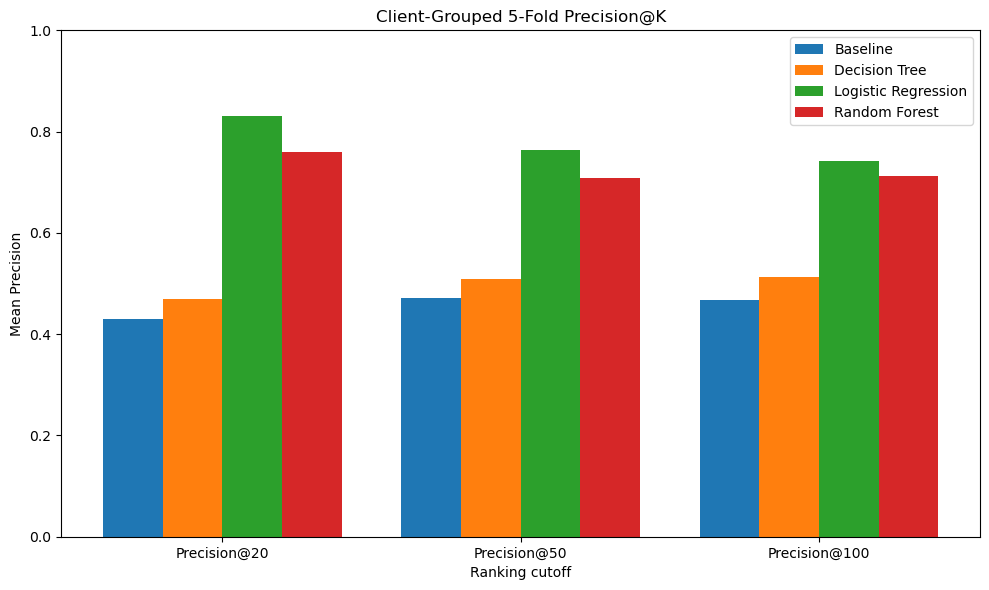

Saved: ..\outputs\charts\client_grouped_precision_at_k.png


In [90]:
# Main paper figure — Precision@K comparison

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Create the figure output directory here so this section
# can run independently and still work top-to-bottom.
FIGURE_DIR = Path("../outputs/charts")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

models = five_fold_results["Model"].tolist()

k_values = [20, 50, 100]
x = np.arange(len(k_values))
width = 0.20

plt.figure(figsize=(10, 6))

for i, model in enumerate(models):
    row = five_fold_results[
        five_fold_results["Model"] == model
    ].iloc[0]

    means = [
        row["P20_mean"],
        row["P50_mean"],
        row["P100_mean"],
    ]

    plt.bar(
        x + (i - 1.5) * width,
        means,
        width,
        label=model
    )

plt.xticks(
    x,
    ["Precision@20", "Precision@50", "Precision@100"]
)

plt.ylabel("Mean Precision")
plt.xlabel("Ranking cutoff")
plt.title("Client-Grouped 5-Fold Precision@K")

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

figure_path = FIGURE_DIR / "client_grouped_precision_at_k.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

In [91]:
# Save the five-fold results for reproducibility

results_output_path = OUTPUT_DIR / "client_grouped_precision_at_k_summary.csv"

five_fold_results.to_csv(
    results_output_path,
    index=False
)

paper_output_path = OUTPUT_DIR / "client_grouped_precision_at_k_paper_table.csv"

paper_results.to_csv(
    paper_output_path,
    index=False
)

print("Saved:")
print(results_output_path)
print(paper_output_path)

Saved:
..\outputs\client_grouped_precision_at_k_summary.csv
..\outputs\client_grouped_precision_at_k_paper_table.csv


## 5. Limitations

*What this work cannot claim.*


This analysis has several important limitations.

### 1. Observational data

The study uses historical observational data. The model identifies patterns associated with declining performance, but it does not establish causality.

A high-ranked page is therefore not automatically a page that will improve after being refreshed.

### 2. Label construction

The binary target is derived from the observed `trend_direction` field. This simplifies a multi-state performance pattern into a declining/non-declining classification problem.

That definition is useful for the prioritization task but does not capture every possible reason a page may require attention.

### 3. Client and dataset coverage

The results describe the distribution represented in the Flyrank internship dataset. They should not be assumed to generalize to every website, industry, search environment, or future dataset.

### 4. Historical features

The model learns from historical content and performance signals. Search behavior, algorithms, content standards, competition, and website conditions can change over time.

### 5. Ranking metric

Precision@K evaluates the concentration of relevant pages near the top of the queue. It does not measure the eventual business impact of acting on those recommendations.

### 6. Human review remains necessary

The output is intended to prioritize investigation, not replace editorial or SEO judgment. A high-ranked recommendation should still be reviewed for context before action.

### 7. Reproducibility constraints

The public repository contains the analysis code and public-safe artifacts, but the original production-scale data and private client information cannot be published. As a result, an external reader may be able to inspect the workflow without having access to every underlying production record.

### Honest claim

The strongest conclusion supported by this study is:

> **Under the client-grouped validation design, the evaluated machine-learning models produced stronger top-of-queue ranking performance than the simple baseline, with Logistic Regression producing the strongest mean Precision@20. The result supports machine learning as a decision-support layer for content refresh prioritization, not as proof of causal traffic improvement.**

In [92]:
# Section 5 — validation facts supporting the limitations discussion

print("Validation design: 5-fold GroupKFold")
print("Grouping variable:", GROUP_COLUMN)
print("Primary metric:", PRIMARY_METRIC)
print("Number of folds:", N_SPLITS)

if "fold_summary_df" in globals():
    print("\nMaximum client overlap across folds:",
          fold_summary_df["client_overlap"].max())

Validation design: 5-fold GroupKFold
Grouping variable: client_id
Primary metric: Precision@K
Number of folds: 5

Maximum client overlap across folds: 0


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*



The model output should be treated as a prioritized review queue rather than an automatic action list.

### Recommendation 1 — Use Logistic Regression for the primary review queue

Use Logistic Regression as the primary ranking approach for the content-refresh review queue because it produced the strongest mean Precision@20 under the client-grouped five-fold validation design.

The model achieved a mean Precision@20 of 0.83 (SD = 0.045), compared with 0.43 (SD = 0.179) for the baseline.

### Recommendation 2 — Keep the baseline as a benchmark

The existing baseline should remain in the workflow as a simple reference point.

Future model versions should demonstrate measurable improvement over this benchmark before replacing it.

### Recommendation 3 — Attach reason codes to recommendations

A ranked score alone is not enough for a human workflow. Each recommendation should include an interpretable reason code describing the main observed signals associated with the recommendation.

Examples include:

- stale content;
- high visibility with declining performance;
- weak engagement;
- other observed performance signals.

Reason codes make the queue easier for a reviewer to understand, challenge, and act on.

### Recommendation 4 — Require human review before action

The model should identify pages for investigation rather than automatically trigger a content refresh.

Reviewers should consider factors such as:

- search intent;
- content relevance;
- business importance;
- recent changes;
- competitive context;
- whether the observed decline appears meaningful.

### Recommendation 5 — Monitor performance and retrain when necessary

If this approach were used operationally, performance should be monitored over time.

Useful monitoring signals include:

- Precision@K on newly labeled data;
- changes in feature distributions;
- changes in the proportion of declining pages;
- performance by content type or client;
- model drift;
- changes in baseline performance.

### Recommended decision flow

**Rank → Explain → Review → Act → Measure → Retrain**

This converts the model from a prediction exercise into a repeatable decision-support workflow.

In [93]:
# Section 6 — action playbook

recommendations = pd.DataFrame([
    {
        "Rank": 1,
        "Recommendation": "Use Logistic Regression for the primary review queue",
        "Why": "Strongest mean Precision@20 under client-grouped validation",
        "Action": "Rank candidate content and send the highest-priority items for review",
    },
    {
        "Rank": 2,
        "Recommendation": "Keep the baseline as a benchmark",
        "Why": "Provides a simple reference for measuring model value",
        "Action": "Track model Precision@K against baseline Precision@K",
    },
    {
        "Rank": 3,
        "Recommendation": "Attach reason codes",
        "Why": "Makes recommendations easier for humans to interpret",
        "Action": "Show the main observed signals behind each recommendation",
    },
    {
        "Rank": 4,
        "Recommendation": "Require human review before refresh",
        "Why": "The model identifies associations, not causal interventions",
        "Action": "Review intent, context, relevance, and recent changes",
    },
    {
        "Rank": 5,
        "Recommendation": "Monitor and retrain",
        "Why": "Search and content patterns can change over time",
        "Action": "Track Precision@K, drift, label rates, and segment performance",
    },
])

display(recommendations)

,Rank,Recommendation,Why,Action
0,1,Use Logistic Regression for the primary review...,Strongest mean Precision@20 under client-group...,Rank candidate content and send the highest-pr...
1,2,Keep the baseline as a benchmark,Provides a simple reference for measuring mode...,Track model Precision@K against baseline Preci...
2,3,Attach reason codes,Makes recommendations easier for humans to int...,Show the main observed signals behind each rec...
3,4,Require human review before refresh,"The model identifies associations, not causal ...","Review intent, context, relevance, and recent ..."
4,5,Monitor and retrain,Search and content patterns can change over time,"Track Precision@K, drift, label rates, and seg..."


In [94]:
# Save the action playbook for use in the research paper

from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

recommendations_path = OUTPUT_DIR / "capstone_ranked_recommendations.csv"

recommendations.to_csv(
    recommendations_path,
    index=False
)

print("Saved:", recommendations_path)

Saved: ..\outputs\capstone_ranked_recommendations.csv


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*


The deployed research page will embed a small set of artifacts that make the analysis easier to inspect.

### 1. Precision@K comparison

A comparison of the baseline and evaluated machine-learning models across Precision@20, Precision@50, and Precision@100.

The chart uses the mean results from the five client-grouped validation folds.

### 2. Client-grouped validation summary

A table documenting the number of training and test observations and clients in each validation fold. This provides evidence that client groups were kept separate during evaluation.

### 3. Ranked recommendation table

The action playbook translates the modeling results into practical recommendations for a content-review workflow.

### 4. Paper-ready results table

A compact table reports mean Precision@K together with the standard deviation across the five validation folds.

### Public-safety check

All artifacts are designed for the public research page. They use aggregated results and public-safe labels and do not include client names, private URLs, search queries, credentials, or other identifying information.

The artifacts are intended to support inspection and interpretation of the research findings rather than reproduce every exploratory analysis performed during the internship.

In [95]:
#Artifact directories

from pathlib import Path

OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("Figure directory:", FIGURE_DIR)
print("Table directory:", TABLE_DIR)

Output directory: ..\outputs
Figure directory: ..\outputs\charts
Table directory: ..\outputs\tables


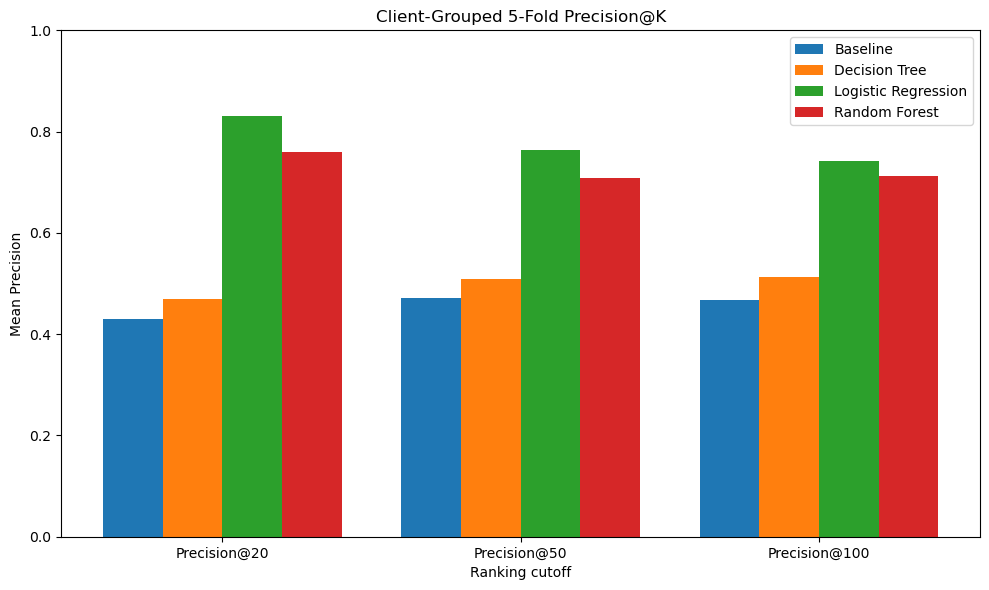

Saved: ..\outputs\charts\client_grouped_precision_at_k.png


In [96]:
# Artifact 1 — Mean Precision@K comparison

import matplotlib.pyplot as plt
import numpy as np

models = five_fold_results["Model"].tolist()

k_labels = ["Precision@20", "Precision@50", "Precision@100"]

means = {
    "Precision@20": five_fold_results["P20_mean"].tolist(),
    "Precision@50": five_fold_results["P50_mean"].tolist(),
    "Precision@100": five_fold_results["P100_mean"].tolist(),
}

x = np.arange(len(k_labels))
width = 0.20

plt.figure(figsize=(10, 6))

for i, model in enumerate(models):
    values = [
        means["Precision@20"][i],
        means["Precision@50"][i],
        means["Precision@100"][i],
    ]

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=model
    )

plt.xticks(x, k_labels)
plt.ylabel("Mean Precision")
plt.xlabel("Ranking cutoff")
plt.title("Client-Grouped 5-Fold Precision@K")

plt.ylim(0, 1)
plt.legend()

plt.tight_layout()

precision_chart_path = (
    FIGURE_DIR / "client_grouped_precision_at_k.png"
)

plt.savefig(
    precision_chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", precision_chart_path)

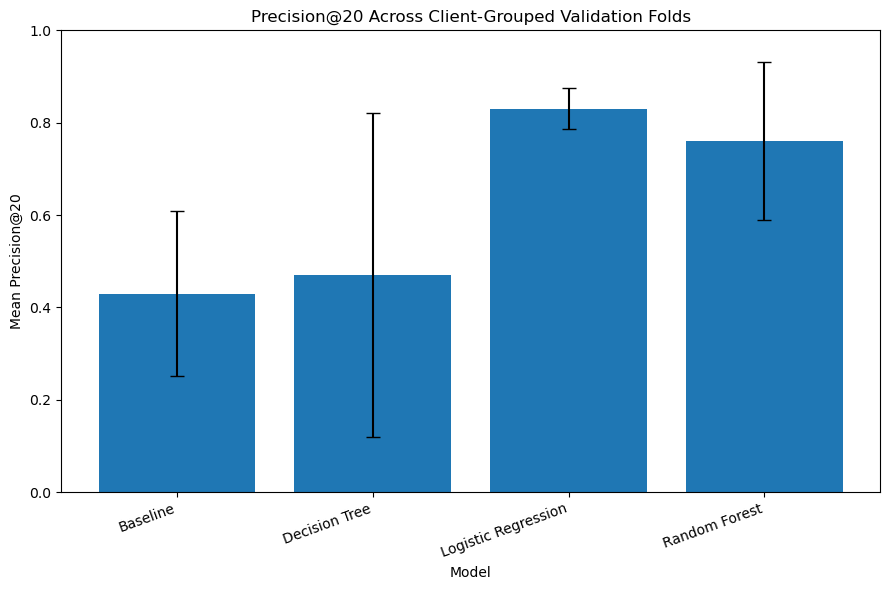

Saved: ..\outputs\charts\precision_at_20_with_variability.png


In [97]:
# Artifact 2 — Precision@20 mean and standard deviation

plt.figure(figsize=(9, 6))

plt.bar(
    five_fold_results["Model"],
    five_fold_results["P20_mean"],
    yerr=five_fold_results["P20_std"],
    capsize=5
)

plt.ylabel("Mean Precision@20")
plt.xlabel("Model")
plt.title("Precision@20 Across Client-Grouped Validation Folds")

plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")

plt.tight_layout()

stability_chart_path = (
    FIGURE_DIR / "precision_at_20_with_variability.png"
)

plt.savefig(
    stability_chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", stability_chart_path)

In [98]:
# Artifact 3 — Client-grouped validation summary

if "fold_summary_df" not in globals():
    raise NameError(
        "fold_summary_df is not available. "
        "Run the Section 3 validation cell first."
    )

display(fold_summary_df)

,fold,train_rows,test_rows,train_clients,test_clients,client_overlap
0,1,22992,7008,31,1,0
1,2,24269,5731,25,7,0
2,3,24247,5753,24,8,0
3,4,24245,5755,24,8,0
4,5,24247,5753,24,8,0


In [99]:
validation_table_path = (
    TABLE_DIR / "client_grouped_validation_summary.csv"
)

fold_summary_df.to_csv(
    validation_table_path,
    index=False
)

print("Saved:", validation_table_path)

Saved: ..\outputs\tables\client_grouped_validation_summary.csv


In [100]:
# Artifact 4 — Paper-ready Precision@K table

display(paper_results)

paper_table_path = (
    TABLE_DIR / "client_grouped_precision_at_k.csv"
)

paper_results.to_csv(
    paper_table_path,
    index=False
)

print("Saved:", paper_table_path)


,Model,P@20,P@50,P@100
0,Baseline,0.430 ± 0.179,0.472 ± 0.167,0.468 ± 0.139
1,Decision Tree,0.470 ± 0.351,0.508 ± 0.346,0.512 ± 0.328
2,Logistic Regression,0.830 ± 0.045,0.764 ± 0.091,0.742 ± 0.116
3,Random Forest,0.760 ± 0.171,0.708 ± 0.164,0.712 ± 0.145


Saved: ..\outputs\tables\client_grouped_precision_at_k.csv


In [101]:
# Artifact 5 — Ranked recommendation table

display(recommendations)

recommendations_table_path = (
    TABLE_DIR / "ranked_recommendations.csv"
)

recommendations.to_csv(
    recommendations_table_path,
    index=False
)

print("Saved:", recommendations_table_path)

,Rank,Recommendation,Why,Action
0,1,Use Logistic Regression for the primary review...,Strongest mean Precision@20 under client-group...,Rank candidate content and send the highest-pr...
1,2,Keep the baseline as a benchmark,Provides a simple reference for measuring mode...,Track model Precision@K against baseline Preci...
2,3,Attach reason codes,Makes recommendations easier for humans to int...,Show the main observed signals behind each rec...
3,4,Require human review before refresh,"The model identifies associations, not causal ...","Review intent, context, relevance, and recent ..."
4,5,Monitor and retrain,Search and content patterns can change over time,"Track Precision@K, drift, label rates, and seg..."


Saved: ..\outputs\tables\ranked_recommendations.csv


In [102]:
# Final artifact inventory

artifact_paths = [
    precision_chart_path,
    stability_chart_path,
    validation_table_path,
    paper_table_path,
    recommendations_table_path,
]

print("Capstone artifacts:")
print("-" * 60)

for path in artifact_paths:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path}")

Capstone artifacts:
------------------------------------------------------------
FOUND: ..\outputs\charts\client_grouped_precision_at_k.png
FOUND: ..\outputs\charts\precision_at_20_with_variability.png
FOUND: ..\outputs\tables\client_grouped_validation_summary.csv
FOUND: ..\outputs\tables\client_grouped_precision_at_k.csv
FOUND: ..\outputs\tables\ranked_recommendations.csv


## ML-12 Closing Artifacts

### 5-Minute Demo Outline

#### The problem

Content teams may have many pages that could potentially be refreshed, so the practical challenge is deciding which pages deserve attention first.

The research question was: **Can machine learning improve content refresh prioritization compared with a simple baseline?**

#### The data

The analysis uses the public-safe, pseudonymized FlyRank ML Internship dataset, combining content-level information with historical search-performance signals.

The data contains approximately 79 million daily performance records covering historical observations through June 2026.

#### The methodology

I defined a binary declining-performance label from the observed `trend_direction` field and evaluated Logistic Regression, Decision Tree, and Random Forest models against a simple baseline.

The primary evaluation used five-fold GroupKFold validation grouped by `client_id`, so records from the same client were not shared between training and test sets within a fold.

The main metric was Precision@K at K = 20, 50, and 100 because the practical use case is ranking a limited review queue.

#### The results

Logistic Regression produced the strongest mean Precision@20 at **0.83 (SD = 0.045)** across the five client-grouped folds.

The baseline achieved **0.43 (SD = 0.179)**.

Random Forest achieved **0.76 (SD = 0.171)**, while the Decision Tree achieved **0.47 (SD = 0.351)**.

The result shows that Logistic Regression provided the strongest and comparatively stable top-of-queue ranking performance under the evaluation design.

#### From model to action

The model output is translated into a ranked review queue rather than an automatic refresh list.

Each recommendation can be accompanied by reason codes, followed by human review before action.

The proposed workflow is:

**Rank → Explain → Review → Act → Measure → Retrain**

####  Honest conclusion

The model improves the ranking of pages associated with observed declining performance in this dataset.

However, the analysis is observational and does not prove that refreshing a page will cause traffic or search performance to improve.

The main contribution is therefore a measurable decision-support approach for prioritizing content review, together with a validation design and action playbook that can be monitored over time.

### Social-Post Cut

I started this project thinking the hardest part of machine learning would be building the model.

I was wrong.

The harder part was figuring out what the model should actually help someone decide.

For my FlyRank ML Internship capstone, I built and evaluated models for prioritizing content refresh opportunities, compared them against a simple baseline, and used 5-fold client-grouped validation to test how well the ranking approach held up across clients.

Logistic Regression achieved a mean Precision@20 of **0.83**, compared with **0.43** for the baseline.

But the biggest lesson wasn't the score.

It was learning that a good ML project doesn't end with:

**"Here's my model."**

It ends with:

**"Here's the decision it supports, here's the evidence, here's what it cannot claim, and here's what someone should do next."**

That shift in thinking has probably been one of the most valuable parts of my ML journey so far.

### 3-Sentence Employer-Facing Summary

I built and evaluated a machine-learning ranking system to prioritize content refresh opportunities using a large pseudonymized search-performance dataset. I compared Logistic Regression, Decision Tree, and Random Forest approaches against a baseline and used five-fold client-grouped validation, with Logistic Regression achieving the strongest mean Precision@20 of 0.83 versus 0.43 for the baseline. I translated the model output into a human-review action playbook with reason codes, monitoring considerations, and explicit limits on what the model can claim.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
